In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
data = {
      "Area": [1000, 1200, 1500, 1800, 2000,
               2200, 2500, 2800, 3000, 3200,
               1100, 1400, 1700, 2100, 2600],
      "Bedrooms": [2, 2, 3, 3, 3,
                   4, 4, 4, 5, 5,
                   2, 3, 3, 4, 4],
      "Price": [150000, 170000, 220000, 250000, 280000,
                300000, 350000, 380000, 420000, 450000,
                160000, 210000, 240000, 290000, 360000]
}

df = pd.DataFrame(data)
df.head()

,Area,Bedrooms,Price
0,1000,2,150000
1,1200,2,170000
2,1500,3,220000
3,1800,3,250000
4,2000,3,280000


In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary")
df.describe()

Dataset shape: (15, 3)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Area      15 non-null     int64
 1   Bedrooms  15 non-null     int64
 2   Price     15 non-null     int64
dtypes: int64(3)
memory usage: 492.0 bytes

Statistical summary


,Area,Bedrooms,Price
count,15.000000,15.000000,15.000000
mean,2006.666667,3.400000,282000.000000
std,703.528522,0.985611,94354.952932
min,1000.000000,2.000000,150000.000000
25%,1450.000000,3.000000,215000.000000
50%,2000.000000,3.000000,280000.000000
75%,2550.000000,4.000000,355000.000000
max,3200.000000,5.000000,450000.000000


In [6]:
X = df[["Area", "Bedrooms"]]
y = df["Price"]

print("Features (X):")
display(X.head())

print("Target (y):")
display(y.head())

Features (X):


,Area,Bedrooms
0,1000,2
1,1200,2
2,1500,3
3,1800,3
4,2000,3


Target (y):


,Price
0,150000
1,170000
2,220000
3,250000
4,280000


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (12, 2)
Testing features: (3, 2)
Training targets: (12,)
Testing targets: (3,)


In [9]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Model training completed!
Coefficient: [ 128.52375344 3755.39850805]
Intercept: 9766.391833529691


In [10]:
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.values)

print("\nPredicted Prices:")
print(y_pred)

Actual Prices:
[450000 210000 150000]

Predicted Prices:
[439819.3953671  200965.84216726 145800.94228504]


In [11]:
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("R² Score", r2)


Mean Absolute Error (MAE): 7804.6067268681845
R² Score 0.9959743491243661


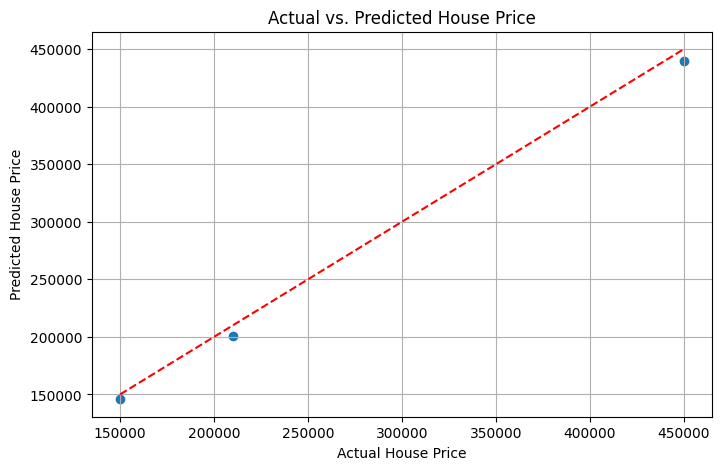

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs. Predicted House Price")
plt.grid(True)
plt.show()

In [14]:
new_house = pd.DataFrame({
    "Area": [2000],
    "Bedrooms": [4],
})

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 281835.49273655284
